> **AI-use disclosure.** This notebook was developed with the help of **Claude Code (Anthropic)** in VS Code.
> * **AI-generated / AI-assisted:** code structure, the data-processing and model code (in `src/` and the cells below),
>   plotting code, and first drafts of the explanatory markdown.
> * **Done by the student (B. G. M. Prabuddhi):** choice of the problem and the Sri Lankan dataset, making and approving
>   the data and modelling decisions, reviewing the code, running the notebook, checking the outputs, and interpreting the results.
>
> Full details: [`AI_DISCLOSURE.md`](../AI_DISCLOSURE.md).

# 05 · Stacking and voting

**Goal.** Combine the strongest bagging and boosting models (Random Forest, XGBoost, LightGBM, CatBoost) and test
whether a combination beats its members.

* **Voting (averaging):** every base model gets the same weight; the prediction is the mean.
* **Stacking:** a **meta-learner** (here `RidgeCV`) learns *how much to trust each base model* from their out-of-fold
  predictions. With time-series data those out-of-fold predictions must also respect time: each base model is trained
  on the past and predicts the next block (`TimeSeriesSplit`). sklearn's `StackingRegressor` refuses `TimeSeriesSplit`
  (it needs folds that cover every row), so `src/models.py` contains a short `TimeSeriesStackingRegressor` that does
  exactly this.

**When does combining help?** Only when the base models make **different** errors. If their errors are highly
correlated, averaging or stacking them is like asking the same expert twice. So before stacking we measure the
correlation between the base models' validation errors.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # make `src` importable from the notebook
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, viz
viz.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30)

import time
from src import models as M, evaluate as E, features as F
cfg, splits, feats = M.load_data()
tr, va, te = splits["train"], splits["val"], splits["test"]
BASE = ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]

## 1. Are the base learners diverse? Correlation of validation errors (2022)

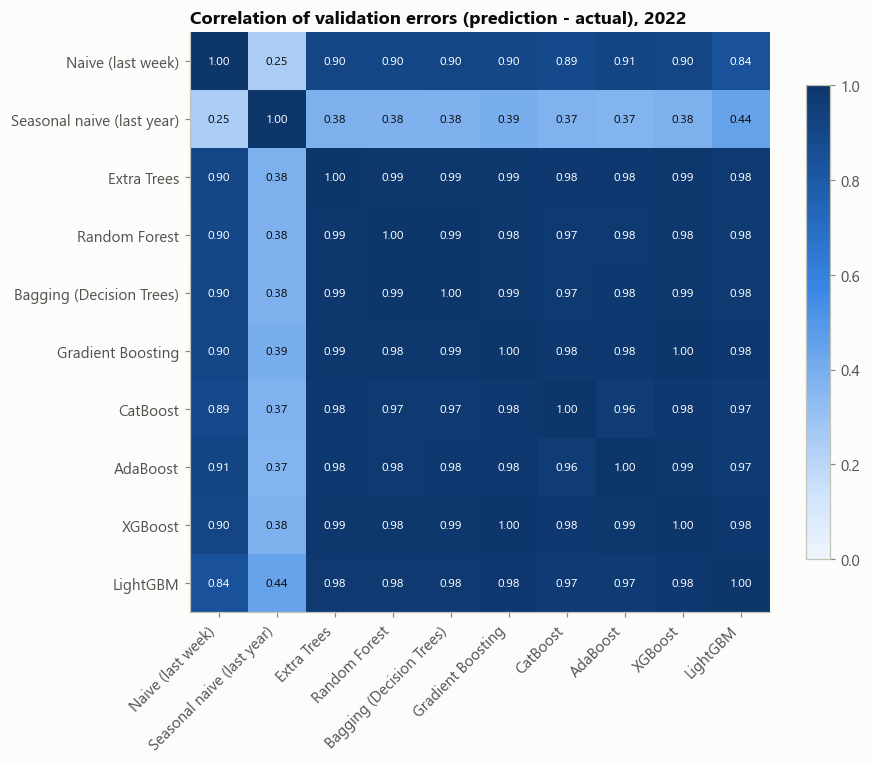

mean pairwise error correlation among the 4 stacking base models: 0.978 (min 0.970, max 0.985)
mean correlation of the naive baseline's errors with the base models: 0.883


In [2]:
vp = E.load_predictions("val")
models_so_far = [c for c in vp.columns if c not in ("district", "target_date", "target")]
errors = vp[models_so_far].sub(vp.target, axis=0)
corr = errors.corr()
order = [m for m in E.results_table().model if m in corr.index]
corr = corr.loc[order, order]

fig, ax = plt.subplots(figsize=(8.5, 7))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq", viz.SEQ_BLUE)
im = ax.imshow(corr.values, cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=45, ha="right"); ax.set_yticks(range(len(order)), order)
for i in range(len(order)):
    for j in range(len(order)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else viz.INK)
ax.grid(False); ax.set_title("Correlation of validation errors (prediction - actual), 2022")
fig.colorbar(im, ax=ax, shrink=0.8); viz.save(fig, "stacking_error_correlation"); plt.show()

base_corr = corr.loc[BASE, BASE].values[np.triu_indices(len(BASE), 1)]
print(f"mean pairwise error correlation among the 4 stacking base models: {base_corr.mean():.3f} "
      f"(min {base_corr.min():.3f}, max {base_corr.max():.3f})")
print(f"mean correlation of the naive baseline's errors with the base models: {corr.loc[E.NAIVE_NAME, BASE].mean():.3f}")

## 2. Build the base models with their tuned settings (from notebooks 03-04)

In [3]:
def tuned(name):
    params, rounds = M.load_best_params(name)
    return M.build_final(name, params, cfg, n_rounds=rounds)
estimators = [(name, tuned(name)) for name in BASE]
for n, e in estimators:
    print(n, "->", type(e.named_steps["model"].regressor).__name__)

Random Forest -> RandomForestRegressor
XGBoost -> XGBRegressor
LightGBM -> LGBMRegressor
CatBoost -> CatBoostRegressor


## 3. Stacking: RF + XGBoost + LightGBM + CatBoost → RidgeCV (time-ordered out-of-fold)

In [4]:
stack = M.TimeSeriesStackingRegressor(estimators, n_splits=4)
t0 = time.time(); stack.fit(tr[feats], tr.target); stack_time = time.time() - t0
stack_val, stack_test = stack.predict(va[feats]), stack.predict(te[feats])
E.record_result("Stacking (RF+XGB+LGBM+Cat -> Ridge)", "Stacking", te, stack_test, stack_time, val=va, val_pred=stack_val)
print(f"fitted in {stack_time:.0f}s; meta-learner alpha = {stack.final_estimator_.alpha_:.3g}, "
      f"intercept = {stack.final_estimator_.intercept_:.3f}")
print("meta-learner weights (on log1p predictions):")
print(stack.meta_weights_.round(3).to_string())
print("sum of weights:", round(stack.meta_weights_.sum(), 3))

fitted in 27s; meta-learner alpha = 10, intercept = -0.077
meta-learner weights (on log1p predictions):
Random Forest    0.373
XGBoost          0.405
LightGBM         0.024
CatBoost         0.246
sum of weights: 1.048


## 4. Voting: simple average of the same four models

In [5]:
from sklearn.ensemble import VotingRegressor
vote = VotingRegressor(estimators=[(n, e) for n, e in estimators], n_jobs=1)
vote, vote_time = M.fit_timed(vote, tr, feats)
E.record_result("Voting (RF+XGB+LGBM+Cat, mean)", "Stacking", te, vote.predict(te[feats]), vote_time,
                val=va, val_pred=vote.predict(va[feats]))
res = E.results_table()
res.round(3)

,model,family,MAE,RMSE,R2,sMAPE,MAE_vs_naive_pct,RMSE_vs_naive_pct,MAE_normal,MAE_outbreak,val_MAE,train_time_s
0,Naive (last week),Baseline,14.949,37.586,0.867,46.210,0.000,0.000,7.432,21.062,11.547,0.00
1,Seasonal naive (last year),Baseline,37.753,95.695,0.140,79.931,-152.540,-154.600,17.630,54.118,20.114,0.00
2,Extra Trees,Bagging,14.506,39.089,0.856,43.813,2.963,-3.997,6.199,21.262,10.340,4.98
3,Random Forest,Bagging,14.520,37.472,0.868,44.349,2.874,0.304,6.073,21.389,10.393,8.49
4,Bagging (Decision Trees),Bagging,14.701,38.281,0.862,44.465,1.659,-1.848,6.031,21.752,10.449,6.69
5,Gradient Boosting,Boosting,15.447,43.010,0.826,43.936,-3.327,-14.429,5.894,23.216,10.430,4.09
6,CatBoost,Boosting,15.714,44.105,0.817,44.693,-5.115,-17.343,6.139,23.501,10.562,0.60
7,AdaBoost,Boosting,16.021,47.361,0.789,45.136,-7.169,-26.006,6.327,23.904,10.484,1.74
8,XGBoost,Boosting,16.508,51.886,0.747,44.382,-10.425,-38.045,5.926,25.113,10.442,0.30
9,LightGBM,Boosting,18.593,50.949,0.756,46.669,-24.376,-35.553,5.983,28.849,10.576,0.48


## 5. Did combining help? Base models vs their combinations

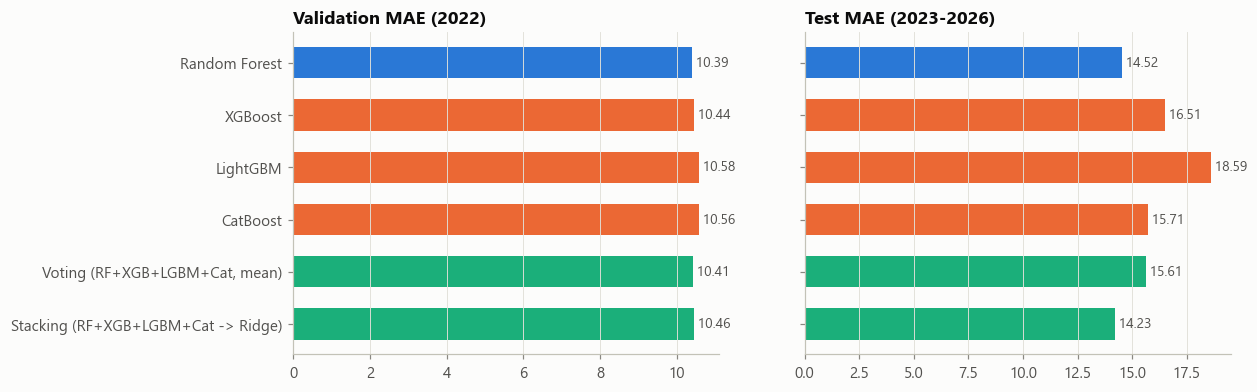

,val_MAE,MAE,RMSE,MAE_normal,MAE_outbreak,MAE_vs_naive_pct
model,,,,,,
Random Forest,10.393,14.520,37.472,6.073,21.389,2.874
XGBoost,10.442,16.508,51.886,5.926,25.113,-10.425
LightGBM,10.576,18.593,50.949,5.983,28.849,-24.376
CatBoost,10.562,15.714,44.105,6.139,23.501,-5.115
"Voting (RF+XGB+LGBM+Cat, mean)",10.407,15.610,43.194,5.868,23.533,-4.421
Stacking (RF+XGB+LGBM+Cat -> Ridge),10.455,14.234,36.884,6.692,20.367,4.784


In [6]:
show = BASE + ["Voting (RF+XGB+LGBM+Cat, mean)", "Stacking (RF+XGB+LGBM+Cat -> Ridge)"]
r = E.results_table().set_index("model").loc[show]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, title in [(axes[0], "val_MAE", "Validation MAE (2022)"), (axes[1], "MAE", "Test MAE (2023-2026)")]:
    colors = [viz.FAMILY_COLORS["Stacking"] if "Stack" in m or "Vot" in m else
              viz.FAMILY_COLORS["Bagging"] if m == "Random Forest" else viz.FAMILY_COLORS["Boosting"] for m in show]
    ax.barh(show[::-1], r[col].values[::-1], color=colors[::-1], height=0.6)
    for i, v in enumerate(r[col].values[::-1]):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=9, color=viz.INK_2)
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
viz.save(fig, "stacking_vs_base"); plt.show()
r[["val_MAE", "MAE", "RMSE", "MAE_normal", "MAE_outbreak", "MAE_vs_naive_pct"]].round(3)

## 6. Save the stacker

In [7]:
M.save_model(stack, "stacking.joblib")
M.register("stacking", "Stacking (RF+XGB+LGBM+Cat -> Ridge)", "stacking.joblib",
           meta_weights=stack.meta_weights_.round(4).to_dict())
stk = E.results_table().query("family == 'Stacking'").sort_values("val_MAE")
best = stk.iloc[0]["model"]
print("best combination by validation MAE:", best)
if best.startswith("Voting"):
    M.save_model(vote, "voting.joblib")
    M.register("stacking_best", best, "voting.joblib")
else:
    M.register("stacking_best", best, "stacking.joblib")

saved models/stacking.joblib (15.9 MB)
best combination by validation MAE: Voting (RF+XGB+LGBM+Cat, mean)


saved models/voting.joblib (15.5 MB)


## Key findings

* **The base learners are not diverse:** their 2022 validation errors are **97.8% correlated** on average (0.970–0.985).
  They lean on the same lagged-case features and miss the same surges; even the naive baseline's errors correlate 0.88 with
  theirs. In theory, stacking helps most when errors differ, so a large "diversity bonus" was not expected.
* **Stacking (RF + XGBoost + LightGBM + CatBoost → RidgeCV) still beat every single model on test:** MAE **14.23**
  (**+4.8%** vs naive; RMSE 36.88, +1.9%), with the best outbreak-week MAE of any pure ensemble (20.37 vs 21.06 naive), at
  the cost of slightly worse normal weeks (6.69).
* **Why it helped: a learned bias correction.** Meta-weights: RF **0.37**, XGBoost **0.40**, CatBoost **0.25**,
  LightGBM 0.02. They sum to **1.05**, so the stack scales the (log) forecast up slightly, partly offsetting the base models'
  shared under-prediction of surges.
* **Voting (simple mean) did not help:** −4.4% vs naive (MAE 15.61). Three of its four members are boosters that
  under-predict outbreaks, and equal weights cannot correct that. It has the better *validation* MAE of the two (10.41 vs
  10.46), so the pre-set rule saves it as the stacking-family winner.
* **Validation vs test disagree:** on calm 2022, Voting < Stacking; on the outbreak-heavy test, Stacking ≪ Voting.
* Training cost: stacking 27 s (4 base models × 4 time-ordered folds + refit), voting 10 s; files ~16 MB each.